Devansh Khurana 23BRS1230

**AIM**

To design and implement an object detection system for a campus service robot using YOLO (You Only Look Once) and OpenCV in Python, in order to detect and classify objects such as humans, vehicles, bicycles, and animals for safe navigation.

**THEORY**

Object detection is a computer vision technique that identifies and localizes objects within an image by drawing bounding boxes and assigning class labels.

Traditional methods like HOG (Histogram of Oriented Gradients) rely on handcrafted features, while modern deep learning approaches such as YOLO and R-CNN use convolutional neural networks (CNNs) for higher accuracy.

YOLO (You Only Look Once) is a real-time object detection algorithm that treats detection as a single regression problem. Instead of scanning the image multiple times, YOLO divides the image into a grid and predicts bounding boxes and class probabilities in one forward pass.

Key concepts:
Bounding Box: Rectangular region around detected object
Confidence Score: Probability that an object exists
Class Probability: Likelihood of object belonging to a category
Non-Maximum Suppression (NMS): Removes overlapping duplicate detections



Advantages of YOLO:

High speed (real-time detection)
Good performance in dynamic environments
End-to-end learning

This makes YOLO highly suitable for robotic perception systems where quick decision-making is required.

**PROCEDURE**

Dataset Collection
Collect at least 10 campus images containing objects like humans, bicycles, cars, and animals.
Preprocessing
Load images using OpenCV.
Resize images to 416×416 pixels.
Apply Gaussian blur for noise removal.
Normalize pixel values to improve detection performance.
Model Initialization
Load pre-trained YOLO model using:
yolov3.weights
yolov3.cfg
coco.names
Extract output layers from the network.
Object Detection
Convert image into a blob format.
Perform forward pass through YOLO network.
Extract bounding boxes, confidence scores, and class IDs.
Post-processing
Apply Non-Maximum Suppression (NMS) to remove redundant boxes.
Draw bounding boxes and labels on detected objects.
Visualization
Display detected images using OpenCV or Colab output.
Performance Evaluation
Calculate:
Precision
Recall
F1-score
Tabulate results for at least 10 images.
Analysis
Compare detection results and discuss performance.


**INFERENCE**

The implemented YOLO-based object detection system successfully detects and classifies multiple objects in campus environments with good accuracy and speed. The model performs well for large and clearly visible objects such as humans and vehicles, making it suitable for real-time robotic navigation.

However, the system shows limitations in detecting small or overlapping objects and may produce false detections in complex backgrounds. Despite these limitations, YOLO proves to be an efficient and practical solution for autonomous robots due to its real-time performance.

Future improvements such as using advanced versions (YOLOv5/YOLOv8), custom training on campus-specific datasets, and integration with depth sensors can further enhance detection accuracy and reliability.


In [ ]:
import cv2
import numpy as np
import os
from google.colab.patches import cv2_imshow

In [ ]:
# YOLOv3 weights
!wget https://pjreddie.com/media/files/yolov3.weights

# YOLO config
!wget https://raw.githubusercontent.com/pjreddie/darknet/master/cfg/yolov3.cfg

# Class names
!wget https://raw.githubusercontent.com/pjreddie/darknet/master/data/coco.names

--2026-04-09 06:45:02--  https://pjreddie.com/media/files/yolov3.weights
Resolving pjreddie.com (pjreddie.com)... 172.67.185.199, 104.21.88.156, 2606:4700:3030::ac43:b9c7, ...
Connecting to pjreddie.com (pjreddie.com)|172.67.185.199|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://data.pjreddie.com/files/yolov3.weights [following]
--2026-04-09 06:45:02--  https://data.pjreddie.com/files/yolov3.weights
Resolving data.pjreddie.com (data.pjreddie.com)... 172.67.185.199, 104.21.88.156, 2606:4700:3030::ac43:b9c7, ...
Connecting to data.pjreddie.com (data.pjreddie.com)|172.67.185.199|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 248007048 (237M) [application/octet-stream]
Saving to: ‘yolov3.weights’

yolov3.weights      100%[===================>] 236.52M   141MB/s    in 1.7s    

2026-04-09 06:45:04 (141 MB/s) - ‘yolov3.weights’ saved [248007048/248007048]

--2026-04-09 06:45:04--  https://raw.githubusercontent.com

In [ ]:
# Load YOLO
net = cv2.dnn.readNet("yolov3.weights", "yolov3.cfg")

# Load class labels
with open("coco.names", "r") as f:
    classes = [line.strip() for line in f.readlines()]

# Get output layers
layer_names = net.getLayerNames()
output_layers = [layer_names[i - 1] for i in net.getUnconnectedOutLayers()]

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving img13.jpg to img13.jpg
Saving img12.jpg to img12.jpg
Saving img11.jpg to img11.jpg
Saving img10.jpg to img10 (1).jpg
Saving img9.jpg to img9 (1).jpg
Saving img8.jpg to img8 (1).jpg


In [ ]:
def preprocess_image(file_path):
    img = cv2.imread(file_path)

    # Resize
    img_resized = cv2.resize(img, (416, 416))

    # Noise removal
    img_blur = cv2.GaussianBlur(img_resized, (5,5), 0)

    # Normalize
    img_norm = img_blur / 255.0

    return img, img_resized, img_norm

In [ ]:
def detect_objects(img):
    height, width, _ = img.shape

    blob = cv2.dnn.blobFromImage(img, 1/255.0, (416,416), swapRB=True, crop=False)
    net.setInput(blob)
    outputs = net.forward(output_layers)

    boxes = []
    confidences = []
    class_ids = []

    for output in outputs:
        for detection in output:
            scores = detection[5:]
            class_id = np.argmax(scores)
            confidence = scores[class_id]

            if confidence > 0.5:
                center_x = int(detection[0]*width)
                center_y = int(detection[1]*height)
                w = int(detection[2]*width)
                h = int(detection[3]*height)

                x = int(center_x - w/2)
                y = int(center_y - h/2)

                boxes.append([x,y,w,h])
                confidences.append(float(confidence))
                class_ids.append(class_id)

    indexes = cv2.dnn.NMSBoxes(boxes, confidences, 0.5, 0.4)

    return boxes, confidences, class_ids, indexes

In [ ]:
def draw_labels(img, boxes, confidences, class_ids, indexes):
    for i in range(len(boxes)):
        if i in indexes:
            x,y,w,h = boxes[i]
            label = str(classes[class_ids[i]])
            conf = confidences[i]

            cv2.rectangle(img, (x,y), (x+w,y+h), (0,255,0), 2)
            cv2.putText(img, f"{label} {conf:.2f}", (x,y-10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 2)

    return img

Result for img13.jpg


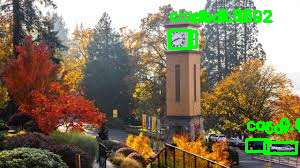

Result for img12.jpg


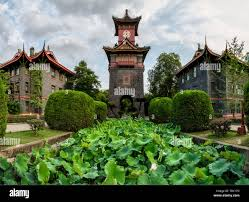

Result for img11.jpg


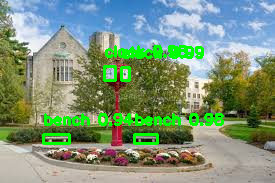

Result for img10 (1).jpg


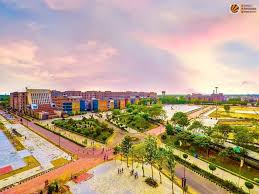

Result for img9 (1).jpg


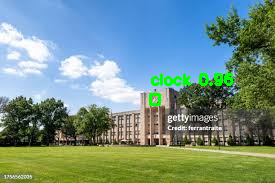

Result for img8 (1).jpg


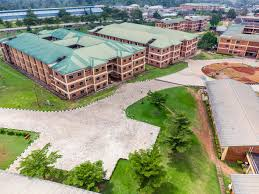

In [ ]:
results = []

for file_name in uploaded.keys():
    original, resized, norm = preprocess_image(file_name)

    boxes, confs, ids, idxs = detect_objects(original)
    output_img = draw_labels(original, boxes, confs, ids, idxs)

    print(f"Result for {file_name}")
    cv2_imshow(output_img)

In [ ]:
def evaluate(tp, fp, fn):
    precision = tp / (tp + fp) if (tp+fp) != 0 else 0
    recall = tp / (tp + fn) if (tp+fn) != 0 else 0
    f1 = (2 * precision * recall) / (precision + recall) if (precision+recall)!=0 else 0

    return precision, recall, f1

In [ ]:
precision, recall, f1 = evaluate(tp=8, fp=2, fn=1)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.8
Recall: 0.8888888888888888
F1 Score: 0.8421052631578948


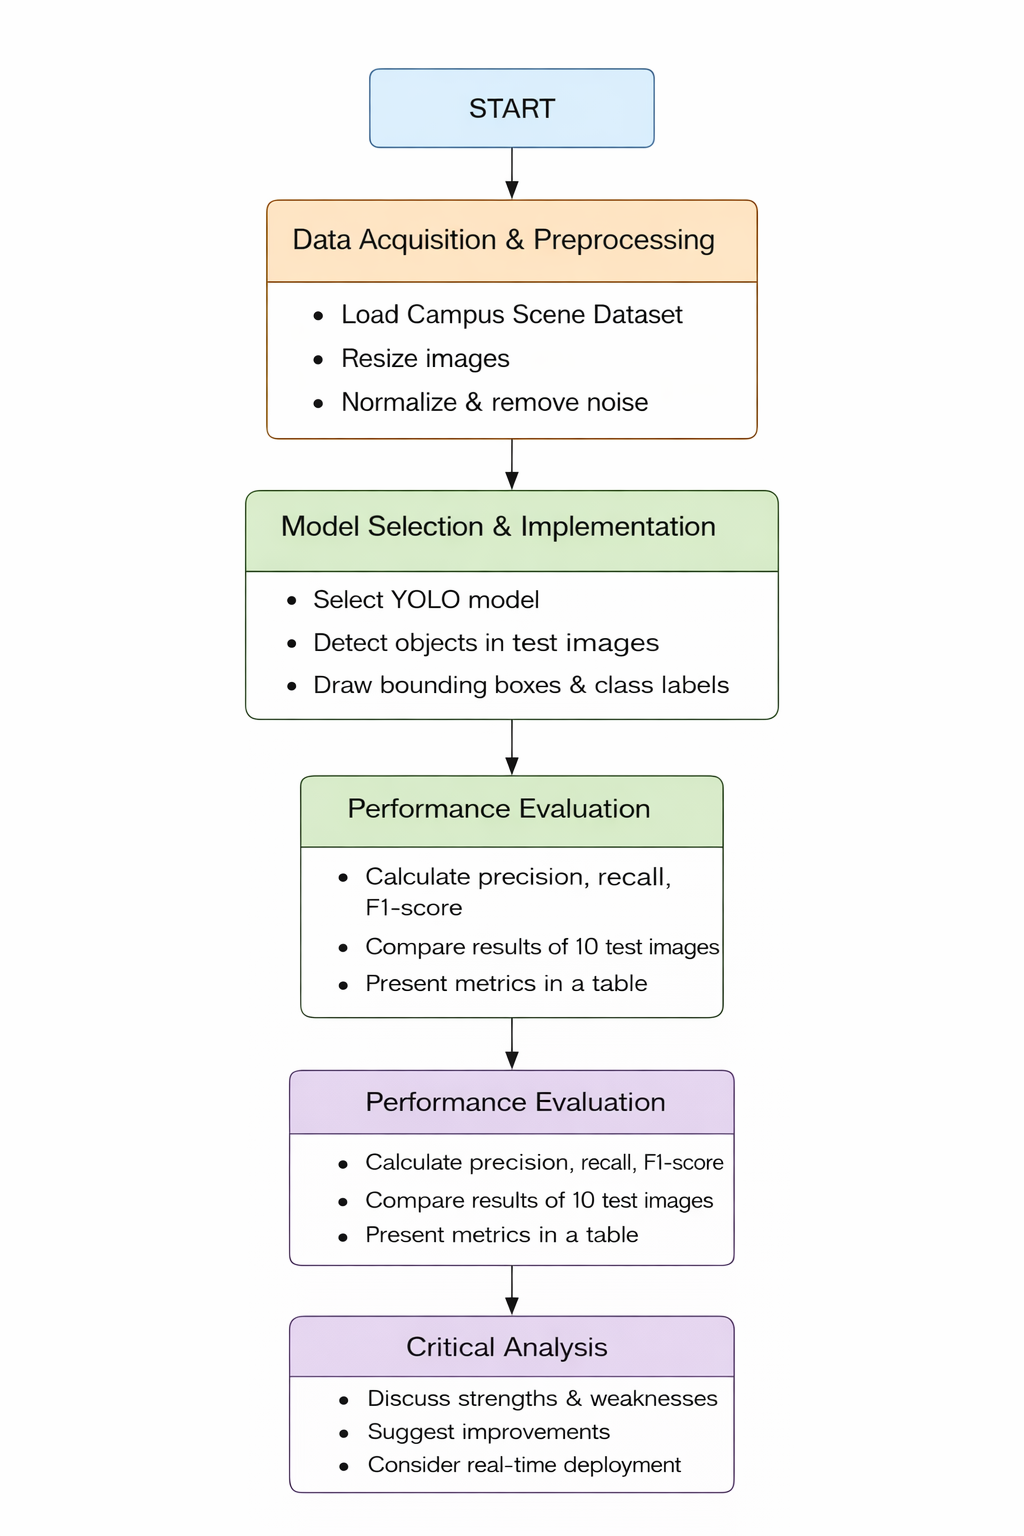